# Forecast vs. Actual: Can a simple model flag revenue surprises early?
*Learning project. Rewrite this introduction in your own words before publishing.*

At month-end close I compare actual results with forecasts and investigate the gaps. This project asks the same question with public data: **if a planner had forecast each quarter's revenue in advance, which quarters would have landed far enough from plan to deserve investigation, and how much of that gap would a Japanese parent company see as currency rather than business performance?**

- **Data:** quarterly revenue from SEC XBRL filings for three Atlanta-headquartered companies (Coca-Cola, UPS, Delta Air Lines); monthly USD/JPY rates from FRED.
- **Methods:** rolling one-quarter-ahead forecasts with three models, variance flags, and a yen-based operating-vs-FX variance split.

## 0. Setup
Runs in Google Colab or Jupyter. The SEC asks every automated request to identify itself, so put **your own name and email** in `USER_AGENT`.

In [1]:
# !pip install pandas requests matplotlib statsmodels   # uncomment if a package is missing
import io, time, warnings
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
from statsmodels.tsa.holtwinters import ExponentialSmoothing

warnings.filterwarnings("ignore")   # hide statsmodels convergence messages

USER_AGENT = "Wei Ji jiwei20190909@gmail.com"   # <-- your real name and email

COMPANIES = {            # SEC CIK numbers; all three use a December 31 fiscal year end
    "Coca-Cola": 21344,
    "UPS": 1090727,
    "Delta Air Lines": 27904,
}
REVENUE_TAGS = [         # companies have used different XBRL tags for revenue over the years
    "Revenues",
    "RevenueFromContractWithCustomerExcludingAssessedTax",
    "SalesRevenueNet",
]
START = "2012Q1"         # first quarter to keep
TEST_QUARTERS = 12       # how many recent quarters to forecast one step ahead
THRESHOLD_PCT = 5.0      # flag a quarter when actual misses the forecast by more than this %

## 1. Download company facts from the SEC
Each company's XBRL data arrives as one JSON file. Facts carry a `frame` label: `CY2023Q1` marks a roughly three-month period and `CY2023` a roughly twelve-month period.

In [2]:
def get_company_facts(cik):
    url = f"https://data.sec.gov/api/xbrl/companyfacts/CIK{cik:010d}.json"
    r = requests.get(url, headers={"User-Agent": USER_AGENT}, timeout=30)
    r.raise_for_status()
    time.sleep(0.2)                      # stay well under the SEC's request limit
    return r.json()

In [3]:
facts = {name: get_company_facts(cik) for name, cik in COMPANIES.items()}
print({name: f.get("entityName") for name, f in facts.items()})

{'Coca-Cola': 'COCA COLA CO', 'UPS': 'United Parcel Service, Inc.', 'Delta Air Lines': 'DELTA AIR LINES, INC.'}


## 2. Build a clean quarterly series
Companies file three quarterly reports (10-Q) and one annual report (10-K), and most 10-Ks only report the full year. So **Q4 has to be derived: Q4 = full year − (Q1 + Q2 + Q3)**, the same way an accountant backs into a fourth quarter. The `source` column records where every number came from, and the check below keeps only an unbroken run of quarters.

In [4]:
def frames_for_tag(company_facts, tag):
    """{frame: value} for one us-gaap tag in USD (duration frames only)."""
    try:
        rows = company_facts["facts"]["us-gaap"][tag]["units"]["USD"]
    except KeyError:
        return {}
    return {r["frame"]: r["val"] for r in rows
            if "frame" in r and not r["frame"].endswith("I")}

def quarterly_revenue(company_facts, tags=REVENUE_TAGS):
    per_tag = {t: frames_for_tag(company_facts, t) for t in tags}
    years = sorted({int(f[2:6]) for d in per_tag.values() for f in d})
    rows = []
    for y in years:
        for q in range(1, 5):
            for t in tags:                   # the first tag that covers this quarter wins
                d = per_tag[t]
                if f"CY{y}Q{q}" in d:
                    rows.append((pd.Period(f"{y}Q{q}", freq="Q"), d[f"CY{y}Q{q}"], t))
                    break
                if q == 4 and f"CY{y}" in d and all(f"CY{y}Q{k}" in d for k in (1, 2, 3)):
                    q4 = d[f"CY{y}"] - sum(d[f"CY{y}Q{k}"] for k in (1, 2, 3))
                    rows.append((pd.Period(f"{y}Q4", freq="Q"), q4, t + " (Q4 = FY - Q1..Q3)"))
                    break
    df = pd.DataFrame(rows, columns=["quarter", "revenue", "source"]).set_index("quarter")
    return df.sort_index()

def unbroken_tail(df):
    """Keep the latest run of consecutive quarters (models need a series without gaps)."""
    full = pd.period_range(df.index.min(), df.index.max(), freq="Q")
    missing = full.difference(df.index)
    if len(missing):
        df = df[df.index > missing.max()]
    return df, list(missing.astype(str))

series, sources = {}, {}
for name, f in facts.items():
    df = quarterly_revenue(f)
    df = df[df.index >= pd.Period(START, freq="Q")]
    df, missing = unbroken_tail(df)
    print(f"{name}: {len(df)} quarters, {df.index.min()} to {df.index.max()}; gaps dropped: {missing or 'none'}")
    if len(df) < TEST_QUARTERS + 12:
        print(f"  -> skipping {name}: not enough consecutive quarters")
        continue
    series[name] = df["revenue"] / 1e9          # USD billions
    sources[name] = df["source"]

# which XBRL tags were used for each company, and how many Q4s were derived
pd.DataFrame({name: s.value_counts() for name, s in sources.items()}).fillna(0).astype(int)

Coca-Cola: 35 quarters, 2018Q1 to 2026Q3; gaps dropped: ['2017Q4']
UPS: 59 quarters, 2012Q1 to 2026Q3; gaps dropped: none
Delta Air Lines: 59 quarters, 2012Q1 to 2026Q3; gaps dropped: none


,Coca-Cola,UPS,Delta Air Lines
source,,,
RevenueFromContractWithCustomerExcludingAssessedTax,0,18,25
RevenueFromContractWithCustomerExcludingAssessedTax (Q4 = FY - Q1..Q3),0,5,6
Revenues,27,36,28
Revenues (Q4 = FY - Q1..Q3),8,0,0


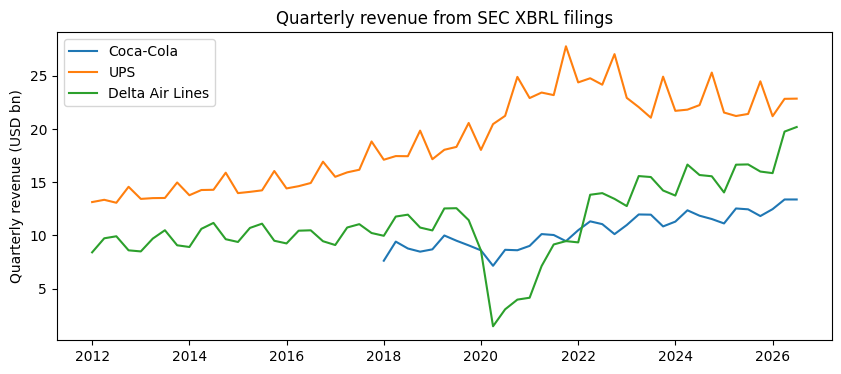

In [5]:
fig, ax = plt.subplots(figsize=(10, 4))
for name, s in series.items():
    ax.plot(s.index.to_timestamp(), s.values, label=name)
ax.set_ylabel("Quarterly revenue (USD bn)")
ax.set_title("Quarterly revenue from SEC XBRL filings")
ax.legend()
plt.show()

## 3. Rolling one-quarter-ahead forecasts
This mirrors how a planner works: before each quarter, forecast it using only the data available at that time, then compare with the actual once it is reported.

- **Same quarter last year:** the simplest seasonal baseline.
- **Last year + growth:** the same quarter last year, scaled by the most recent four quarters' year-over-year growth.
- **Holt-Winters:** exponential smoothing with a trend and a seasonal pattern (statsmodels).

Accuracy is measured with MAPE, the average absolute percentage error, where lower is better.

In [6]:
def same_quarter_last_year(train):
    return train.iloc[-4]

def last_year_plus_growth(train):
    growth = train.iloc[-4:].sum() / train.iloc[-8:-4].sum()
    return train.iloc[-4] * growth

def holt_winters(train):
    try:
        model = ExponentialSmoothing(train.values, trend="add", seasonal="mul",
                                     seasonal_periods=4, initialization_method="estimated").fit()
        return float(model.forecast(1)[0])
    except Exception:
        return np.nan                    # e.g. too little data

MODELS = {"Same quarter last year": same_quarter_last_year,
          "Last year + growth": last_year_plus_growth,
          "Holt-Winters": holt_winters}

def rolling_forecasts(s, n_test=TEST_QUARTERS):
    out = {m: {} for m in MODELS}
    for i in range(len(s) - n_test, len(s)):
        train = s.iloc[:i]               # only what was known before quarter i
        for m, fn in MODELS.items():
            out[m][s.index[i]] = fn(train)
    fc = pd.DataFrame(out)
    fc["Actual"] = s.iloc[-n_test:]
    return fc

def mape(actual, forecast):
    return (abs(actual - forecast) / actual).mean() * 100

forecasts, scores = {}, {}
for name, s in series.items():
    forecasts[name] = rolling_forecasts(s)
    scores[name] = {m: mape(forecasts[name]["Actual"], forecasts[name][m]) for m in MODELS}

score_table = pd.DataFrame(scores).T.round(1)
score_table                              # MAPE in %, lower is better

,Same quarter last year,Last year + growth,Holt-Winters
Coca-Cola,4.5,3.0,2.2
UPS,4.0,4.8,2.8
Delta Air Lines,7.0,6.5,4.3


## 4. Which quarters would a planner investigate?
For each company, use the model with the lowest MAPE and flag every quarter where the actual result missed the forecast by more than `THRESHOLD_PCT`.

In [7]:
flags = []
for name, fc in forecasts.items():
    best = score_table.loc[name].idxmin()
    variance_pct = (fc["Actual"] - fc[best]) / fc[best] * 100
    for q, v in variance_pct.items():
        if abs(v) > THRESHOLD_PCT:
            flags.append({"company": name, "quarter": str(q), "model": best,
                          "forecast (USD bn)": round(fc.loc[q, best], 2),
                          "actual (USD bn)": round(fc.loc[q, "Actual"], 2),
                          "variance %": round(v, 1)})

flag_table = pd.DataFrame(flags)
flag_table if len(flag_table) else "No quarter missed its forecast by more than the threshold."

,company,quarter,model,forecast (USD bn),actual (USD bn),variance %
0,Coca-Cola,2025Q1,Holt-Winters,11.89,11.13,-6.4
1,UPS,2023Q4,Holt-Winters,23.01,24.92,8.3
2,UPS,2026Q2,Holt-Winters,21.35,22.83,6.9
3,Delta Air Lines,2024Q2,Holt-Winters,15.72,16.66,6.0
4,Delta Air Lines,2024Q3,Holt-Winters,17.20,15.68,-8.8
5,Delta Air Lines,2024Q4,Holt-Winters,14.38,15.56,8.2
6,Delta Air Lines,2025Q1,Holt-Winters,14.82,14.04,-5.3
7,Delta Air Lines,2026Q2,Holt-Winters,18.32,19.76,7.8


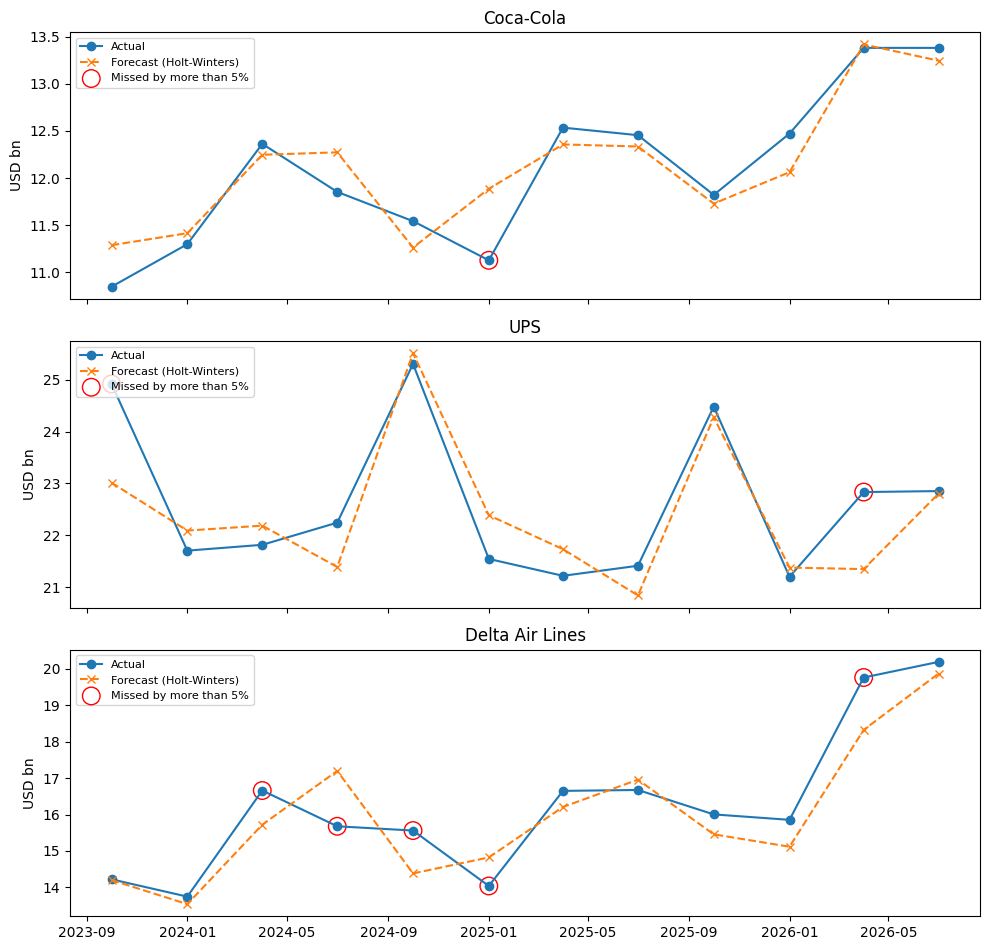

In [8]:
fig, axes = plt.subplots(len(forecasts), 1, figsize=(10, 3.2 * len(forecasts)), sharex=True)
for ax, (name, fc) in zip(np.atleast_1d(axes), forecasts.items()):
    best = score_table.loc[name].idxmin()
    t = fc.index.to_timestamp()
    variance_pct = (fc["Actual"] - fc[best]) / fc[best] * 100
    hit = (variance_pct.abs() > THRESHOLD_PCT).values
    ax.plot(t, fc["Actual"], marker="o", label="Actual")
    ax.plot(t, fc[best], marker="x", linestyle="--", label=f"Forecast ({best})")
    ax.scatter(t[hit], fc["Actual"].values[hit], s=160, facecolors="none", edgecolors="red",
               label=f"Missed by more than {THRESHOLD_PCT:.0f}%")
    ax.set_title(name)
    ax.set_ylabel("USD bn")
    ax.legend(loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

## 5. The same results through a Japanese parent's eyes
A Japanese parent consolidating one of these businesses would set its plan in yen at a **budget rate** and report at the **actual rate**. The yen gap between plan and actual then splits exactly into two parts:

- **Operating variance** = (actual USD − forecast USD) × budget rate
- **FX variance** = actual USD × (actual rate − budget rate)

Here the budget rate is the average USD/JPY rate in Q4 of the previous year, roughly what a planner would know when setting the annual plan. Change `FX_COMPANY` to look at another company.

In [9]:
def get_usdjpy_quarterly():
    # If this download fails, save the CSV from https://fred.stlouisfed.org/series/EXJPUS
    # and replace the next three lines with: fx = pd.read_csv("EXJPUS.csv")
    url = "https://fred.stlouisfed.org/graph/fredgraph.csv?id=EXJPUS"   # monthly average, yen per US dollar
    r = requests.get(url, headers={"User-Agent": USER_AGENT}, timeout=30)
    r.raise_for_status()
    fx = pd.read_csv(io.StringIO(r.text))
    fx.columns = ["date", "usdjpy"]                    # FRED's header names have changed over time
    fx["usdjpy"] = pd.to_numeric(fx["usdjpy"], errors="coerce")
    fx = fx.dropna()
    fx["quarter"] = pd.to_datetime(fx["date"]).dt.to_period("Q")
    return fx.groupby("quarter")["usdjpy"].mean()

In [10]:
usdjpy = get_usdjpy_quarterly()

FX_COMPANY = "Coca-Cola" if "Coca-Cola" in forecasts else next(iter(forecasts))
fc = forecasts[FX_COMPANY]
best = score_table.loc[FX_COMPANY].idxmin()

rows = []
for q in fc.index:
    budget_rate = usdjpy.get(pd.Period(f"{q.year - 1}Q4", freq="Q"))
    actual_rate = usdjpy.get(q)
    if budget_rate is None or actual_rate is None:
        continue                                   # rate not published yet
    usd_actual, usd_forecast = fc.loc[q, "Actual"], fc.loc[q, best]
    rows.append({
        "quarter": str(q),
        "budget rate": budget_rate,
        "actual rate": actual_rate,
        "plan (JPY bn)": usd_forecast * budget_rate,
        "actual (JPY bn)": usd_actual * actual_rate,
        "operating variance (JPY bn)": (usd_actual - usd_forecast) * budget_rate,
        "FX variance (JPY bn)": usd_actual * (actual_rate - budget_rate),
    })

fx_table = pd.DataFrame(rows).set_index("quarter").round(1)
fx_table

,budget rate,actual rate,plan (JPY bn),actual (JPY bn),operating variance (JPY bn),FX variance (JPY bn)
quarter,,,,,,
2023Q4,141.5,147.8,1597.1,1603.0,-62.3,68.1
2024Q1,147.8,148.6,1686.8,1678.9,-17.2,9.3
2024Q2,147.8,155.9,1809.6,1927.1,17.1,100.4
2024Q3,147.8,148.9,1813.4,1765.2,-61.9,13.8
2024Q4,147.8,152.5,1664.3,1760.1,41.3,54.5
2025Q1,152.5,152.4,1812.4,1695.7,-115.6,-1.1
2025Q2,152.5,144.5,1884.1,1811.3,27.2,-100.0
2025Q3,152.5,147.5,1880.7,1837.3,18.3,-61.8
2025Q4,152.5,154.1,1788.5,1822.2,14.0,19.7


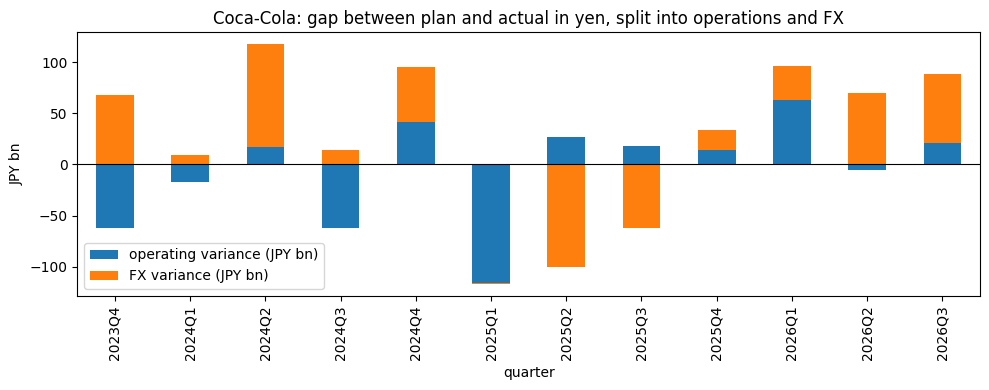

In [11]:
ax = fx_table[["operating variance (JPY bn)", "FX variance (JPY bn)"]].plot(
    kind="bar", stacked=True, figsize=(10, 4))
ax.axhline(0, color="black", linewidth=0.8)
ax.set_ylabel("JPY bn")
ax.set_title(f"{FX_COMPANY}: gap between plan and actual in yen, split into operations and FX")
plt.tight_layout()
plt.show()

## 6. What I found
*Write this section yourself after running the notebook. Use your own numbers.*

- Which model worked best for each company, and why might that be?
- Which quarters were flagged? Check the company's earnings release for those quarters: could a planner have seen it coming?
- In yen, how much of the gap came from FX rather than operations? What would that mean for a U.S. subsidiary setting its annual plan?

## 7. Limitations and next steps
- SEC frames are aligned to calendar quarters; companies with non-December year ends need extra care.
- Q4 is derived, so restatements and acquisitions can distort it.
- Only three simple models; a next step is a regression with business drivers.
- A single budget rate per year is a simplification; real plans may use hedged or monthly rates.